<a href="https://colab.research.google.com/github/tazza11/brigadoon/blob/main/%EA%B0%95%ED%99%94%ED%95%99%EC%8A%B5_5%EA%B0%95_%EC%8B%A4%EC%8A%B5_DQN_%EC%B9%B4%ED%8A%B8%ED%8F%B4_%EB%B2%BD%EB%8F%8C%EA%B9%A8%EA%B8%B0_%EB%A3%A8%EB%82%98%EB%9E%9C%EB%8D%94_%ED%97%88%EA%B9%85%ED%8E%98%EC%9D%B4%EC%8A%A4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 강화학습 5강 — DQN 완전 정복
### 🌙 루나랜더 착륙 → 🚗 뒤집힌 로드스터 → ❌ DQN 의 벽 → 👉 6강 PPO

**AI CITY BUILDERS · Connect AI LAB**

4강까지 두뇌는 **표(Q표)** 였습니다. 얼음 호수는 64칸 × 행동 4개 = 256칸이면 충분했죠.
그런데 착륙선의 상태는 **연속된 숫자** — 칸을 셀 수 없습니다. 그래서 표 대신 **신경망**이 Q 를 계산합니다. 이것이 **DQN (Deep Q-Network)** 입니다.

| 오늘의 이야기 | 셀 | 하는 일 |
|---|---|---|
| ① 🌙 루나랜더 | 02 ~ 12 | DQN 을 **네 조각으로 뜯어 보고**, 다시 합쳐 진짜 착륙선을 착륙시킨다 · 두뇌 속 Q 값 들여다보기 |
| ② 🚗 뒤집힌 로드스터 | 13 | 10월 15일 시연처럼 **뒤집힌 채로 떨어지는 세상**을 직접 만든다 |
| ③ ❌ DQN 의 벽 | 14 ~ 15 | 루나랜더를 푼 **그 DQN 그대로** 학습 → 반짝 배웠다 잊는다, 마지막 두뇌 **0%** · 왜 안 되는지 |
| 🤗 내 모델 공개 | 16 ~ 18 | 착륙 두뇌를 허깅페이스에 올린다 |
| ④ 👉 6강 예고 | 19 | 같은 세상에서 **PPO** 는 착지한다 |

> ▶ **런타임 → 모두 실행** (GPU 필요 없음 · 약 15분). 허깅페이스 업로드(17번 셀)는 토큰을 넣어야 진행됩니다.
> 카트폴 · 벽돌깨기 · 아타리 · MuJoCo 는 맨 아래 **부록**에 있습니다.

## 🔍 DQN 이 뭐예요?

**DQN = Deep Q-Network = 「Q 를 계산하는 신경망」**

| 글자 | 뜻 |
|---|---|
| **D** · Deep | 숫자를 받아 여러 층을 거쳐 답을 계산하는 깊은 신경망 |
| **Q** · 행동가치 | 2~4강의 그 Q — 「이 상태에서 이 행동을 하면 앞으로 받을 점수의 합」을 미리 짐작한 값. 가장 큰 Q 의 행동을 고른다 |
| **N** · Network | 신경망 |

질문은 4강까지와 똑같습니다 — **「지금 이 상태에서 왼쪽은 몇 점? 오른쪽은 몇 점?」**
달라진 건 대답하는 방법뿐입니다. Q표는 **칸을 찾아서** 대답하고, DQN 은 **숫자를 넣어 계산해서** 대답합니다. 표를 채우던 일을 신경망이 배우는 거예요.

**DQN 이 배우는 한 바퀴**
1. **해 보기** — 탐험(ε)하며 행동한다 (2강)
2. **기록** — (상태 · 행동 · 보상 · 다음 상태)를 기억 상자에 쌓는다 (3강)
3. **정답 만들기** — 정답 = 보상 + γ × 다음 상태의 가장 큰 Q (4강) · 목표 두뇌가 계산
4. **차이 줄이기** — 두뇌의 예측을 정답 쪽으로 조금 당긴다 → 다시 1번으로

> 셀마다 움직이며 이해하는 해설 페이지: [aicitybuilders.com/brain](https://www.aicitybuilders.com/brain)

## CELL 01 · 준비

In [1]:
!pip install -q swig
!pip install -q "gymnasium[classic-control,box2d]>=1.0" imageio-ffmpeg huggingface_hub
!apt-get -qq install -y fonts-nanum > /dev/null 2>&1

import os, math, time, json, random, base64, collections
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import gymnasium as gym, imageio
import matplotlib, matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import HTML, display

글꼴경로 = next((p for p in ['/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf',
                            '/System/Library/Fonts/Supplemental/AppleGothic.ttf'] if os.path.exists(p)), None)
if 글꼴경로:
    matplotlib.font_manager.fontManager.addfont(글꼴경로)
    plt.rcParams['font.family'] = matplotlib.font_manager.FontProperties(fname=글꼴경로).get_name()
plt.rcParams['axes.unicode_minus'] = False
def 글꼴(n):
    try: return ImageFont.truetype(글꼴경로, n)
    except Exception: return ImageFont.load_default()

torch.set_num_threads(1)   # 작은 두뇌는 CPU 한 줄이 가장 빠르다
def 영상보기(화면들, 파일, fps=30, 너비=480):
    imageio.mimsave(파일, 화면들, fps=fps, macro_block_size=1)
    display(HTML(f'<video width="{너비}" controls autoplay loop muted><source src="data:video/mp4;base64,'
                 f'{base64.b64encode(open(파일, "rb").read()).decode()}" type="video/mp4"></video>'))
print('✅ 준비 완료 · torch', torch.__version__, '· gymnasium', gym.__version__)

✅ 준비 완료 · torch 2.11.0+cpu · gymnasium 1.4.0


## CELL 02 · 🌙 오늘의 세상 — 루나랜더 (Gymnasium)

이번엔 우리가 만든 게임이 아니라 **Gymnasium 의 `LunarLander-v3`** 입니다. 물리 엔진(Box2D)이 들어간 진짜 시뮬레이터예요. (Gymnasium 은 OpenAI 가 만든 Gym 을 이어받은 환경 모음입니다.)
착륙선을 추진기 세 개로 조종해 깃발 사이 착지대에 사뿐히 내려야 합니다. 로켓 · 드론 · 날아오르는 자동차 — **날아오르는 것보다 내려앉는 게 어렵습니다.**

| 재료 | 루나랜더에서는 |
|---|---|
| 상태 (8개) | 위치 x · y, 속도 x · y, 기울기, 회전 속도, 왼다리 닿음, 오른다리 닿음 |
| 행동 (4개) | 0 쉬기 · 1 왼쪽 엔진 · 2 가운데 엔진 · 3 오른쪽 엔진 |
| 보상 | 착지대로 내려와 멈추면 약 +100~140 · 추락 −100 · 다리가 땅에 닿을 때마다 +10 · 가운데 엔진 한 번 −0.3 · 옆 엔진 −0.03 |
| 성공 | 한 판 **200점 이상** |

In [2]:
env = gym.make('LunarLander-v3', render_mode='rgb_array')
s, _ = env.reset(seed=0)
print('상태 8개 :', np.round(s, 3))
print('행동     :', env.action_space.n, '개 — 0 쉬기 · 1 왼쪽 엔진 · 2 가운데 엔진 · 3 오른쪽 엔진')
점수 = []
for 씨 in range(20):
    s, _ = env.reset(seed=씨); 끝 = False; R = 0
    while not 끝: s, r, t1, t2, _ = env.step(env.action_space.sample()); R += r; 끝 = t1 or t2
    점수.append(round(R))
print('🎲 무작위로 20판 →', 점수, '· 평균', round(np.mean(점수), 1), '(200 이상이 성공)')
s, _ = env.reset(seed=3); 화면들 = []; 끝 = False
while not 끝: s, r, t1, t2, _ = env.step(env.action_space.sample()); 끝 = t1 or t2; 화면들.append(env.render())
영상보기(화면들[::2], 'lunar_random.mp4', fps=25, 너비=420)

상태 8개 : [ 0.006  1.399  0.578 -0.528 -0.007 -0.131  0.     0.   ]
행동     : 4 개 — 0 쉬기 · 1 왼쪽 엔진 · 2 가운데 엔진 · 3 오른쪽 엔진
🎲 무작위로 20판 → [30, -387, -234, -306, -225, -34, -344, -10, -70, -352, -92, -131, -266, -242, -142, -339, -256, -445, -359, -137] · 평균 -217.0 (200 이상이 성공)


## CELL 03 · 왜 표로는 안 될까

4강 얼음 호수의 Q표는 **64칸 × 4행동 = 256개의 숫자**였습니다.
루나랜더의 상태 8개 중 6개는 **연속된 숫자**입니다 (나머지 2개는 다리가 닿았나 0/1). 아주 거칠게, 0.01 간격으로만 잘라도 칸이 몇 개일까요?

In [3]:
s, _ = gym.make('LunarLander-v3').reset(seed=0)
print('루나랜더 상태 :', np.round(s, 3))
칸 = 1
for 이름, 범위 in [('가로 위치', 3.0), ('높이', 3.0), ('가로 속도', 4.0), ('세로 속도', 4.0), ('기울기', 6.3), ('회전 속도', 10.0)]:
    n = int(범위 / 0.01); 칸 *= n
    print(f'  {이름:<6} 0.01 간격으로 자르면 {n:>5}칸')
칸 *= 2 * 2
print(f'\n표로 만들면 상태 칸 수 ≈ {칸:.1e}개 × 행동 4개')
print('얼음 호수 256칸의', f'{칸 * 4 / 256:.1e}', '배 — 우주가 끝날 때까지 착륙해도 다 못 채웁니다.')
print('\n👉 그래서 표 대신 「숫자를 넣으면 Q값이 나오는 함수」, 신경망을 씁니다.')

루나랜더 상태 : [ 0.006  1.399  0.578 -0.528 -0.007 -0.131  0.     0.   ]
  가로 위치  0.01 간격으로 자르면   300칸
  높이     0.01 간격으로 자르면   300칸
  가로 속도  0.01 간격으로 자르면   400칸
  세로 속도  0.01 간격으로 자르면   400칸
  기울기    0.01 간격으로 자르면   630칸
  회전 속도  0.01 간격으로 자르면  1000칸

표로 만들면 상태 칸 수 ≈ 3.6e+16개 × 행동 4개
얼음 호수 256칸의 5.7e+14 배 — 우주가 끝날 때까지 착륙해도 다 못 채웁니다.

👉 그래서 표 대신 「숫자를 넣으면 Q값이 나오는 함수」, 신경망을 씁니다.


## CELL 04 · 두뇌 = 신경망

표는 「칸을 찾아서 꺼내는 것」이고, 신경망은 「숫자를 넣으면 계산해서 내놓는 것」입니다.

```
상태 숫자 8개 ──▶ [ 128 ] ──▶ [ 128 ] ──▶ Q(쉬기) · Q(왼쪽) · Q(가운데) · Q(오른쪽)
```

처음 본 상태라도 **비슷한 상태에서 배운 것**을 바탕으로 Q 를 계산합니다. 이게 표와의 가장 큰 차이입니다.

In [4]:
def 두뇌만들기(상태수, 행동수, 은닉=128):
    return nn.Sequential(nn.Linear(상태수, 은닉), nn.ReLU(), nn.Linear(은닉, 은닉), nn.ReLU(), nn.Linear(은닉, 행동수))

착륙행동 = ['쉬기', '왼쪽 엔진', '가운데 엔진', '오른쪽 엔진']
torch.manual_seed(0); 뇌 = 두뇌만들기(8, 4)
print(뇌)
print('\n두뇌 안의 숫자(가중치) 개수 :', sum(p.numel() for p in 뇌.parameters()), '개 — 이 숫자들을 고치는 게 「배운다」입니다')
with torch.no_grad(): Q = 뇌(torch.from_numpy(s))
for 이름, v in zip(착륙행동, Q): print(f'  Q({이름:<6}) = {float(v):+.3f}')
print('→ 가장 큰 Q :', 착륙행동[int(Q.argmax())], ' (아직 아무것도 모르는 두뇌라 의미 없는 숫자)')

Sequential(
  (0): Linear(in_features=8, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=4, bias=True)
)

두뇌 안의 숫자(가중치) 개수 : 18180 개 — 이 숫자들을 고치는 게 「배운다」입니다
  Q(쉬기    ) = +0.069
  Q(왼쪽 엔진 ) = -0.063
  Q(가운데 엔진) = -0.055
  Q(오른쪽 엔진) = +0.033
→ 가장 큰 Q : 쉬기  (아직 아무것도 모르는 두뇌라 의미 없는 숫자)


## CELL 05 · DQN 조각 ① 해 보기 — 탐험 ε (2강)

처음 두뇌는 아무것도 모릅니다. 두뇌 말만 들으면 늘 같은 버튼만 누르겠죠. 그래서 **ε 의 확률로 아무 버튼이나** 눌러 봅니다.
ε 는 1(전부 아무거나)에서 시작해 점점 줄어 0.02(거의 두뇌 말대로)가 됩니다. — **처음엔 모험, 나중엔 실력.**

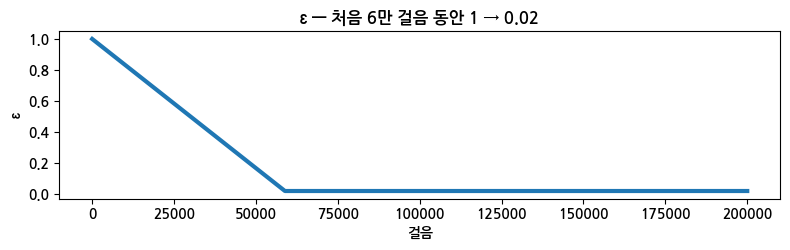

ε = 1.0  → 🎲 🎲 🎲 🎲 🎲 🎲 🎲 🎲 🎲 🎲
ε = 0.5  → 🧠 🎲 🧠 🎲 🧠 🧠 🧠 🧠 🧠 🧠
ε = 0.02 → 🧠 🧠 🧠 🧠 🧠 🧠 🧠 🧠 🧠 🧠


In [5]:
def 고르기(두뇌, 상태, eps):
    if random.random() < eps: return random.randrange(4), '🎲 아무거나'
    with torch.no_grad(): return int(두뇌(torch.from_numpy(상태)).argmax()), '🧠 두뇌 말대로'

총걸음, 탐험기간 = 200_000, 0.3
걸음들 = np.arange(총걸음); eps들 = np.maximum(0.02, 1 - 걸음들 / (총걸음 * 탐험기간))
plt.figure(figsize=(8, 2.6)); plt.plot(걸음들, eps들, lw=3); plt.xlabel('걸음'); plt.ylabel('ε')
plt.title('ε — 처음 6만 걸음 동안 1 → 0.02'); plt.tight_layout(); plt.show()
random.seed(1)
for eps in (1.0, 0.5, 0.02):
    골라 = [고르기(뇌, s, eps) for _ in range(10)]
    print(f'ε = {eps:<4} →', ' '.join('🎲' if '아무' in 방식 else '🧠' for _, 방식 in 골라))

## CELL 06 · DQN 조각 ② 기록 — 기억 상자 (3강)

한 걸음마다 **(상태 · 행동 · 보상 · 다음 상태 · 끝났나)** 한 줄을 기억 상자에 쌓습니다.
배울 때는 방금 겪은 것만 보지 않고, 상자에서 **무작위로 64줄을 꺼내 복습**합니다. 방금 일만 보면 두뇌가 「요즘 일」에만 휘둘리기 때문이에요.

In [6]:
env = gym.make('LunarLander-v3'); 상자 = collections.deque(maxlen=50_000)
st, _ = env.reset(seed=1)
for _ in range(3000):
    a, _ = 고르기(뇌, st, 1.0)
    st2, r, 끝1, 끝2, _ = env.step(a)
    상자.append((st.astype(np.float32), a, float(r), st2.astype(np.float32), float(끝1)))
    st = st2 if not (끝1 or 끝2) else env.reset()[0]
print(f'기억 상자에 {len(상자):,}줄 쌓였습니다. 무작위로 세 줄만 꺼내 보면:\n')
random.seed(3)
for 상태, a, r, 다음, 끝 in random.sample(list(상자), 3):
    print(f'  높이 {상태[1]:+.2f} · 세로속도 {상태[3]:+.2f} · 기울기 {상태[4]:+.2f}  →  행동 {착륙행동[a]:<6}  →  보상 {r:+7.2f}  →  다음 높이 {다음[1]:+.2f}  끝 {int(끝)}')

기억 상자에 3,000줄 쌓였습니다. 무작위로 세 줄만 꺼내 보면:

  높이 +1.48 · 세로속도 -0.24 · 기울기 +0.43  →  행동 오른쪽 엔진  →  보상   -0.18  →  다음 높이 +1.48  끝 0
  높이 +0.43 · 세로속도 -1.24 · 기울기 -0.10  →  행동 가운데 엔진  →  보상   +4.01  →  다음 높이 +0.41  끝 0
  높이 +1.03 · 세로속도 -0.79 · 기울기 +0.21  →  행동 오른쪽 엔진  →  보상   -1.07  →  다음 높이 +1.01  끝 0


## CELL 07 · DQN 조각 ③ 정답 만들기 — γ 와 목표 두뇌 (4강 + 5강 새것)

표가 없으니 「정답 Q」 도 직접 만들어야 합니다. 4강의 그 식입니다.

**정답 = 지금 받은 보상 + γ × (다음 상태에서 가장 큰 Q)**  · 끝났으면 뒤쪽은 0

그런데 「다음 상태의 Q」를 **배우고 있는 두뇌 자신**이 계산하면, 한 번 배울 때마다 정답도 같이 움직입니다. 움직이는 과녁을 쏘는 셈이죠.
그래서 **목표 두뇌**(복사본)를 하나 더 두고, 정답은 목표 두뇌가 계산합니다. 목표 두뇌는 **가끔(500걸음마다)만** 최신 두뇌를 복사해 옵니다. — 과녁을 잠시 고정해 두는 것. **이것이 5강에서 새로 나온 조각입니다.**

In [7]:
목표 = 두뇌만들기(8, 4); 목표.load_state_dict(뇌.state_dict())       # 지금 두뇌를 그대로 복사
감마 = 0.99
상태, a, r, 다음, 끝 = 상자[1234]
with torch.no_grad():
    다음Q = 목표(torch.from_numpy(다음)); 정답 = r + 감마 * float(다음Q.max()) * (1 - 끝)
    예측 = float(뇌(torch.from_numpy(상태))[a])
print(f'행동          : {착륙행동[a]}')
print(f'받은 보상      : {r:+.3f}')
print(f'다음 상태의 Q  : {np.round(다음Q.numpy(), 3)}  → 가장 큰 값 {float(다음Q.max()):+.3f}')
print(f'정답           = {r:+.3f} + {감마} × {float(다음Q.max()):+.3f} × (1 − {int(끝)}) = {정답:+.3f}')
print(f'두뇌의 예측    : {예측:+.3f}   ← 이 차이 {정답 - 예측:+.3f} 를 줄이는 게 다음 조각')

행동          : 쉬기
받은 보상      : +1.646
다음 상태의 Q  : [ 0.059 -0.047 -0.111  0.052]  → 가장 큰 값 +0.059
정답           = +1.646 + 0.99 × +0.059 × (1 − 0) = +1.704
두뇌의 예측    : +0.060   ← 이 차이 +1.644 를 줄이는 게 다음 조각


## CELL 08 · DQN 조각 ④ 차이 줄이기 — 한 걸음 배우기

상자에서 64줄을 꺼내 **예측**과 **정답**을 만들고, 그 차이(손실)가 줄어드는 쪽으로 두뇌 숫자를 **조금** 고칩니다.
이 한 번이 「배운다」의 전부입니다. DQN 은 이걸 **수십만 번** 반복할 뿐이에요.

아까 그 한 줄 — 두뇌의 예측 +0.060  →  300번 배운 뒤 +0.192   (정답 +1.704 쪽으로)


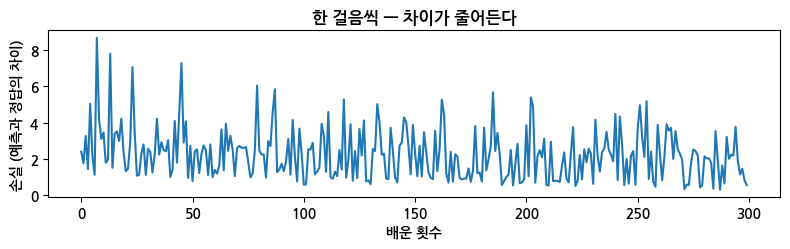

In [8]:
opt = torch.optim.Adam(뇌.parameters(), lr=5e-4)
def 한걸음배우기(배치=64):
    묶음 = random.sample(list(상자), 배치)
    S, A, R, S2, D = [torch.tensor(np.array(x)) for x in zip(*묶음)]
    with torch.no_grad(): 정답 = R.float() + 감마 * 목표(S2).max(1).values * (1 - D.float())      # ③ 목표 두뇌가 만든 정답
    예측 = 뇌(S).gather(1, A.long().unsqueeze(1)).squeeze(1)                                  # 두뇌가 그 행동에 매긴 Q
    손실 = F.smooth_l1_loss(예측, 정답); opt.zero_grad(); 손실.backward(); opt.step()         # ④ 차이 줄이기
    return 손실.item()

with torch.no_grad(): 전 = float(뇌(torch.from_numpy(상태))[a])
기록 = [한걸음배우기() for _ in range(300)]
with torch.no_grad(): 후 = float(뇌(torch.from_numpy(상태))[a])
print(f'아까 그 한 줄 — 두뇌의 예측 {전:+.3f}  →  300번 배운 뒤 {후:+.3f}   (정답 {정답:+.3f} 쪽으로)')
plt.figure(figsize=(8, 2.6)); plt.plot(기록); plt.xlabel('배운 횟수'); plt.ylabel('손실 (예측과 정답의 차이)')
plt.title('한 걸음씩 — 차이가 줄어든다'); plt.tight_layout(); plt.show()

## CELL 09 · 네 조각을 합치면 — DQN 학습 함수

| 어디서 배웠나 | DQN 안에서 | 코드 |
|---|---|---|
| 2강 탐험 | ε 를 1 → 0.02 로 줄이며 아무거나 해 보기 | `eps` |
| 3강 기억 상자 | 겪은 (상태 · 행동 · 보상 · 다음 상태)를 쌓아 두고 **무작위로 꺼내 복습** | `S, A, R, S2, D` |
| 4강 γ | 다음 상태의 가장 큰 Q × γ 를 정답에 더한다 | `감마` |
| **5강 새로 나온 것** | **목표 두뇌** — 정답을 만드는 두뇌는 가끔만 복사해서 흔들리지 않게 | `목표` |

**CELL 05 ~ 08 의 네 조각을 한 함수에 넣었습니다.** 코드 안의 ① ~ ⑤ 표시를 따라가 보세요. 이 함수 하나로 루나랜더도, 뒤에 나올 로드스터도, 부록의 카트폴 · 벽돌깨기도 풉니다.

In [9]:
def DQN학습(환경, 상태수, 행동수, 총걸음, 은닉=128, 학습률=1e-3, 감마=0.99, 탐험기간=0.3, 목표주기=500,
           학습시작=1000, 배치=64, 기억크기=50_000, 씨앗=0, 보고=5000, 평가=None):
    random.seed(씨앗); np.random.seed(씨앗); torch.manual_seed(씨앗)
    q = 두뇌만들기(상태수, 행동수, 은닉); 목표 = 두뇌만들기(상태수, 행동수, 은닉); 목표.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr=학습률)
    S = np.zeros((기억크기, 상태수), np.float32); A = np.zeros(기억크기, np.int64); R = np.zeros(기억크기, np.float32)
    S2 = np.zeros((기억크기, 상태수), np.float32); D = np.zeros(기억크기, np.float32); k = 0; 찬 = 0
    s = 환경.reset(); 판점수 = []; 지금점수 = 0; 최고 = (-1e9, None); 평가기록 = []; t0 = time.time()
    for 걸음 in range(1, 총걸음 + 1):
        eps = max(0.02, 1 - 걸음 / (총걸음 * 탐험기간))                          # ① 탐험 (2강)
        if random.random() < eps: a = random.randrange(행동수)
        else:
            with torch.no_grad(): a = int(q(torch.from_numpy(s)).argmax())
        s2, r, 끝, 진짜끝 = 환경.step(a)
        S[k], A[k], R[k], S2[k], D[k] = s, a, r, s2, float(진짜끝); k = (k + 1) % 기억크기; 찬 = min(찬 + 1, 기억크기)   # ② 기억 상자 (3강)
        지금점수 += r; s = s2
        if 끝: 판점수.append(지금점수); 지금점수 = 0; s = 환경.reset()
        if 걸음 > 학습시작:                                                      # ③ 꺼내서 복습
            i = np.random.randint(0, 찬, 배치)
            with torch.no_grad():
                정답 = torch.from_numpy(R[i]) + 감마 * 목표(torch.from_numpy(S2[i])).max(1).values * (1 - torch.from_numpy(D[i]))   # ④ γ (4강)
            예측 = q(torch.from_numpy(S[i])).gather(1, torch.from_numpy(A[i]).unsqueeze(1)).squeeze(1)
            loss = F.smooth_l1_loss(예측, 정답); opt.zero_grad(); loss.backward(); opt.step()
        if 걸음 % 목표주기 == 0: 목표.load_state_dict(q.state_dict())               # ⑤ 목표 두뇌 (5강)
        if 걸음 % 보고 == 0:
            최근 = np.mean(판점수[-20:]) if 판점수 else 0
            줄 = f'[{걸음:>7,}걸음 | {time.time()-t0:4.0f}초 | ε {eps:.2f}] 최근 20판 평균 {최근:7.1f}'
            if 평가:
                점수 = 평가(q); 평가기록.append((걸음, 점수)); 줄 += f' | 시험 {점수:7.1f}'
                if 점수 >= 최고[0]: 최고 = (점수, {k_: v.clone() for k_, v in q.state_dict().items()}); 줄 += '  🏅'
            print(줄)
    if 평가 and 최고[1] is not None: q.load_state_dict(최고[1])                   # 시험 점수가 가장 좋았던 두뇌를 남긴다
    return q, 판점수, 평가기록

def 곡선(판점수, 제목, 기준=None):
    plt.figure(figsize=(9, 3.2)); plt.plot(판점수, alpha=.25, label='한 판 점수')
    if len(판점수) >= 20: plt.plot(range(19, len(판점수)), np.convolve(판점수, np.ones(20) / 20, 'valid'), lw=2.5, label='최근 20판 평균')
    if 기준: plt.axhline(기준, ls='--', c='gray', label=f'목표 {기준}')
    plt.xlabel('판'); plt.ylabel('점수'); plt.title(제목); plt.legend(); plt.tight_layout(); plt.show()
print('✅ DQN학습() 준비 — ① 탐험 ② 기억 상자 ③ 정답(γ) ④ 차이 줄이기 ⑤ 목표 두뇌')

✅ DQN학습() 준비 — ① 탐험 ② 기억 상자 ③ 정답(γ) ④ 차이 줄이기 ⑤ 목표 두뇌


## CELL 10 · 🌙 루나랜더 착륙 — 학습

상태 8개 · 행동 4개만 알려 주고 `DQN학습()` 에 맡깁니다. 노트북 CPU 로 약 2~5분.
「시험」 점수는 처음 보는 착륙장 5곳에서 잰 점수입니다. 🏅 가 붙은 때의 두뇌를 남깁니다 (오래 배우면 잊어버리기도 하니까요).

In [ ]:
class 착륙환경:
    def __init__(self, 보상가공=None): self.env = gym.make('LunarLander-v3'); self.씨 = 0; self.가공 = 보상가공
    def reset(self): self.씨 += 1; s, _ = self.env.reset(seed=self.씨); self.이전 = s; return s.astype(np.float32)
    def step(self, a):
        s, r, 끝1, 끝2, _ = self.env.step(a)
        if self.가공: r = self.가공(self.이전, a, r, s, 끝1)
        self.이전 = s
        return s.astype(np.float32), r, 끝1 or 끝2, 끝1

def 착륙시험(q, 씨앗들=range(2000, 2005)):          # 채점은 언제나 「원래 보상」으로
    env = gym.make('LunarLander-v3'); 합 = 0
    for 씨 in 씨앗들:
        s, _ = env.reset(seed=씨); 끝 = False
        while not 끝:
            with torch.no_grad(): a = int(q(torch.from_numpy(s.astype(np.float32))).argmax())
            s, r, t1, t2, _ = env.step(a); 합 += r; 끝 = t1 or t2
    return 합 / len(씨앗들)

착륙두뇌, 착륙점수, _ = DQN학습(착륙환경(), 8, 4, 총걸음=200_000, 학습률=5e-4, 감마=0.99, 탐험기간=0.3, 목표주기=500, 배치=128,
                             기억크기=100_000, 보고=20_000, 평가=착륙시험)
착륙최종 = 착륙시험(착륙두뇌, range(2000, 2010))
print(f'\n✅ 다 배운 착륙 두뇌 — 처음 보는 10판 평균 {착륙최종:.1f}점 (200 이상 = 성공)')
곡선(착륙점수, '루나랜더 — DQN 이 스스로 배운 기록', 200)
env = gym.make('LunarLander-v3', render_mode='rgb_array'); s, _ = env.reset(seed=2003); 화면들 = []; 끝 = False
while not 끝:
    with torch.no_grad(): a = int(착륙두뇌(torch.from_numpy(s.astype(np.float32))).argmax())
    s, r, t1, t2, _ = env.step(a); 끝 = t1 or t2; 화면들.append(env.render())
영상보기(화면들[::2], 'lunar.mp4', fps=25, 너비=420)

[ 20,000걸음 |   49초 | ε 0.67] 최근 20판 평균   -64.2 | 시험  -172.0  🏅
[ 40,000걸음 |   87초 | ε 0.33] 최근 20판 평균   -20.3 | 시험   -27.5  🏅


## CELL 11 · 🔍 두뇌 속 들여다보기 — 매 순간의 Q 값

다 배운 두뇌는 매 순간 **네 버튼의 Q 값**을 계산하고 가장 큰 것을 누릅니다. 영상 오른쪽 막대가 그 Q 값이에요.
높이 있을 땐 「쉬기」 가 높다가, 땅이 가까워지면 「가운데 엔진」 이 올라가는 걸 보세요. **표 없이 계산으로 내리는 판단**입니다.

In [ ]:
def Q막대화면(화면, Q, a):
    im = Image.fromarray(화면); W, H = im.size; 판 = Image.new('RGB', (W + 230, H), (6, 8, 11)); 판.paste(im, (0, 0)); d = ImageDraw.Draw(판)
    d.text((W + 16, 14), '두뇌의 Q 값', fill=(184, 255, 92), font=글꼴(18))
    lo, hi = float(Q.min()), float(Q.max()); 폭 = max(hi - lo, 1e-6)
    for k, (이름, v) in enumerate(zip(착륙행동, Q)):
        y = 60 + k * 80; 길이 = 20 + 160 * (float(v) - lo) / 폭
        d.text((W + 16, y), f'{이름}', fill=(255, 255, 255) if k == a else (150, 160, 170), font=글꼴(15))
        d.rectangle([W + 16, y + 24, W + 16 + 길이, y + 44], fill=(184, 255, 92) if k == a else (60, 70, 80))
        d.text((W + 24 + 길이, y + 26), f'{float(v):+.1f}', fill=(220, 220, 220), font=글꼴(13))
    return np.array(판)

env = gym.make('LunarLander-v3', render_mode='rgb_array'); s, _ = env.reset(seed=2003); 화면들 = []; 끝 = False
while not 끝:
    with torch.no_grad(): Q = 착륙두뇌(torch.from_numpy(s.astype(np.float32)))
    a = int(Q.argmax()); 화면들.append(Q막대화면(env.render(), Q, a))
    s, r, t1, t2, _ = env.step(a); 끝 = t1 or t2
영상보기(화면들[::2], 'lunar_q.mp4', fps=25, 너비=620)

## CELL 12 · 🏆 도전 — 착륙 점수를 올려라

아래 숫자를 바꿔 다시 학습시켜 보세요. **채점은 언제나 Gymnasium 원래 보상**으로, 정해진 착륙장 5곳에서 합니다. 학습할 때 쓰는 보상은 `보상가공` 으로 바꿔도 됩니다 — 4강에서 배운 「두뇌가 믿는 보상」이죠.

| 바꿀 것 | 지금 | 생각해 볼 질문 |
|---|---|---|
| `총걸음` | 200,000 | 오래 배우면 늘 좋을까? (카트폴의 「잊어버림」) |
| `학습률` | 0.0005 | 너무 크면? 너무 작으면? |
| `탐험기간` | 0.3 | 탐험을 일찍 멈추면? |
| `감마` | 0.99 | 착지 보상이 먼 미래라면? |
| `보상가공` | 없음 | 연료를 아끼게? 똑바로 서게? 대신 리워드 해킹 주의! |

In [ ]:
총걸음, 학습률, 탐험기간, 감마, 씨앗 = 200_000, 5e-4, 0.3, 0.99, 0     # ✏️ 바꿔 보세요

def 보상가공(이전상태, 행동, 보상, 다음상태, 끝):
    return 보상                                    # ✏️ 예: 기울기가 크면 조금 빼기 → 보상 - 0.5 * abs(다음상태[4])

내두뇌, _, _ = DQN학습(착륙환경(보상가공), 8, 4, 총걸음=총걸음, 학습률=학습률, 감마=감마, 탐험기간=탐험기간, 목표주기=500, 배치=128,
                      기억크기=100_000, 씨앗=씨앗, 보고=40_000, 평가=착륙시험)
import hashlib, datetime
점수카드 = 착륙시험(내두뇌, range(7000, 7005))                       # 처음 보는 착륙장 5곳 (원래 보상)
지문 = hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in 내두뇌.parameters())).hexdigest()[:10]
display(HTML(f'<div style="font-family:sans-serif;border:2px solid #b8ff5c;background:#06080b;color:#fff;padding:18px 22px;max-width:520px">'
             f'<div style="color:#8fd3ff;font-size:12px;letter-spacing:.12em">AI CITY BUILDERS · 강화학습 5강 · 착륙 도전</div>'
             f'<div style="font-size:42px;font-weight:900;margin:6px 0">{점수카드:.1f}점</div>'
             f'<div style="color:#97a3b0;font-size:14px">착륙장 5곳 평균 (원래 보상) · 두뇌 지문 <b style="color:#fff">{지문}</b> · {datetime.date.today()}</div>'
             f'<div style="color:#97a3b0;font-size:13px;margin-top:6px">총걸음 {총걸음:,} · 학습률 {학습률} · 탐험기간 {탐험기간} · 감마 {감마} · 씨앗 {씨앗}</div></div>'))

## CELL 13 · 🚗 뒤집힌 로드스터 — 세상을 직접 만들기

10월 15일, 텍사스 SpaceX 시험장 행사에서 운전자 없는 로드스터 시제품이 램프 끝에서 떨어져 **냉가스(압축 공기) 추진기**로 공중에서 돌아 바퀴로 착지했습니다.
그 장면을 **우리 세상**으로 만들어 봅니다. 루나랜더를 아주 작게 만든 착지 시뮬레이터에, 딱 하나를 바꿉니다 — **뒤집힌 채로 떨어진다.**
(이 영상은 공개 보도 기준이며, 테슬라가 강화학습을 썼다는 발표는 없습니다. 우리는 「그런 문제를 AI 에게 배우게 하면?」 을 실험합니다.)

| 재료 | 뒤집힌 로드스터 |
|---|---|
| 상태 (7개) | 가로 위치 · 높이 · 가로 속도 · 세로 속도 · 기울기(sin · cos 두 숫자로) · 회전 속도 |
| 행동 (4개) | 0 쉬기 · 1 왼쪽 냉가스 · 2 아래 추진기 · 3 오른쪽 냉가스 — 루나랜더와 똑같은 네 버튼 |
| 시작 | 높이 10 · **완전히 뒤집힌 채 (180°)** |
| 보상 | 착지 **+100** · 추락 **−100** · 추진기 연료 − · 착지대에 가까워질수록 · 느려질수록 · 똑바를수록 조금씩 + |
| 착지 | 착지대 위 · **바퀴가 아래(기울기 20° 안)** · 천천히 |

> 💡 기울기를 sin · cos 두 숫자로 주는 이유: 각도 179° 와 −179° 는 사실 거의 같은 자세인데, 숫자 하나로 주면 두뇌는 아주 다르다고 착각합니다. 시계 바늘의 「가로 · 세로 위치」로 주면 그런 착각이 없습니다.

In [ ]:
%%writefile 로드스터_시뮬레이터.py
# 뒤집힌 로드스터 착지 시뮬레이터 — Gymnasium 틀 (Connect AI LAB · 강화학습 5강)
import math, numpy as np, gymnasium as gym
from gymnasium import spaces

class 로드스터(gym.Env):
    """뒤집힌 채로 떨어지는 차를 냉가스 추진기로 돌려 바퀴부터 착지시키기."""
    metadata = {'render_modes': ['rgb_array']}
    G, DT, MAIN, SIDE, MAXT = 1.0, 0.05, 2.2, 1.8, 400            # 중력 · 한 걸음 시간 · 아래 추진기 힘 · 냉가스 힘 · 최대 걸음
    def __init__(self, 시작각=math.pi, 보상=None):
        self.시작각 = 시작각
        self.P = dict(착지=100.0, 추락=-100.0, 연료_가운데=0.3, 연료_옆=0.03, 다듬기=1.0); self.P.update(보상 or {})
        self.action_space = spaces.Discrete(4)                    # 0 쉬기 · 1 왼쪽 냉가스 · 2 아래 추진기 · 3 오른쪽 냉가스
        self.observation_space = spaces.Box(-np.inf, np.inf, (7,), np.float32)
    def _obs(self):
        x, y, vx, vy, th, w = self.s
        return np.array([x / 5, y / 10, vx / 2, vy / 2, math.sin(th), math.cos(th), w / 2], np.float32)
    def _모양(self):                                              # 착지대 · 느림 · 똑바름에 가까울수록 높은 점수
        x, y, vx, vy, th, w = self.s; thn = (th + math.pi) % (2 * math.pi) - math.pi
        return -10 * math.hypot(x / 5, y / 10) - 10 * math.hypot(vx / 2, vy / 2) - 10 * abs(thn)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed); r = self.np_random
        self.s = np.array([r.uniform(-2.5, 2.5), 10.0, r.uniform(-0.8, 0.8), 0.0, math.pi, r.uniform(-0.3, 0.3)], np.float64)
        self.s[4] = self.시작각 * (1 if r.random() < 0.5 else -1) + r.uniform(-0.15, 0.15)   # 뒤집힌 채로 (왼쪽 · 오른쪽 어느 쪽으로든)
        self.t = 0; self.prev = self._모양(); return self._obs(), {}
    def step(self, a):
        x, y, vx, vy, th, w = self.s; P = self.P; r = 0.0
        ax, ay, aw = 0.0, -self.G, 0.0
        if a == 2: ax += -math.sin(th) * self.MAIN; ay += math.cos(th) * self.MAIN; r -= P['연료_가운데']   # 차 바닥 쪽으로 미는 힘
        elif a == 1: aw -= self.SIDE; r -= P['연료_옆']
        elif a == 3: aw += self.SIDE; r -= P['연료_옆']
        vx += ax * self.DT; vy += ay * self.DT; w += aw * self.DT; w *= 0.96
        x += vx * self.DT; y += vy * self.DT; th += w * self.DT
        self.s = np.array([x, y, vx, vy, th, w]); self.t += 1
        sh = self._모양(); r += P['다듬기'] * (sh - self.prev); self.prev = sh
        끝, 결과 = False, ''
        thn = (th + math.pi) % (2 * math.pi) - math.pi
        if y <= 0:
            끝 = True
            if abs(x) <= 1.5 and abs(thn) < 0.35 and vy > -1.5 and abs(vx) < 1.2: r += P['착지']; 결과 = '착지'
            else: r += P['추락']; 결과 = '추락'
        elif abs(x) > 8 or y > 16: 끝 = True; r += P['추락']; 결과 = '밖으로'
        잘림 = self.t >= self.MAXT and not 끝
        return self._obs(), r, 끝, 잘림, {'결과': 결과 or ('시간 끝' if 잘림 else '')}

In [ ]:
from 로드스터_시뮬레이터 import 로드스터
from gymnasium.utils.env_checker import check_env
check_env(로드스터()); print('✅ check_env 통과 — Gymnasium 정식 환경입니다. 이제 아무 두뇌나 붙일 수 있어요.')

def 로드스터그림(e, a=None, 제목='', 색=(184, 255, 92)):
    W, H, sc = 480, 360, 26; ox, gy = W / 2, H - 40
    im = Image.new('RGB', (W, H), (6, 8, 11)); d = ImageDraw.Draw(im)
    d.rectangle([0, gy, W, H], fill=(30, 34, 42)); d.rectangle([ox - 1.5 * sc, gy - 3, ox + 1.5 * sc, gy + 3], fill=(255, 212, 71))
    x, y, vx, vy, th, w = e.s; cx, cy = ox + x * sc, gy - y * sc
    def rot(px, py): c, s = math.cos(th), math.sin(th); return (cx + px * c + py * s, cy - (-px * s + py * c))
    d.polygon([rot(-16, -5), rot(16, -5), rot(16, 3), rot(6, 9), rot(-8, 9), rot(-16, 3)], fill=(225, 40, 50))      # 빨간 차체
    d.polygon([rot(-5, 8), rot(5, 8), rot(2, 12), rot(-3, 12)], fill=(150, 200, 230))                                 # 앞유리
    for wx in (-10, 10): p = rot(wx, -7); d.ellipse([p[0] - 5, p[1] - 5, p[0] + 5, p[1] + 5], fill=(30, 30, 30), outline=(160, 160, 160))
    if a == 2: d.polygon([rot(-5, -9), rot(5, -9), rot(0, -26)], fill=(255, 140, 40))
    if a == 1: d.polygon([rot(16, 2), rot(16, -3), rot(28, 0)], fill=(143, 211, 255))
    if a == 3: d.polygon([rot(-16, 2), rot(-16, -3), rot(-28, 0)], fill=(143, 211, 255))
    thn = math.degrees((th + math.pi) % (2 * math.pi) - math.pi)
    d.text((12, 10), 제목, fill=색, font=글꼴(18)); d.text((12, 36), f'높이 {y:4.1f} · 세로속도 {vy:+.2f} · 기울기 {thn:+5.0f}°', fill=(200, 210, 220), font=글꼴(13))
    return np.array(im)

def 로드스터영상(정책, 씨앗, 제목, 파일, 색=(184, 255, 92)):
    e = 로드스터(); o, _ = e.reset(seed=씨앗); 화면들 = []; 끝 = 잘림 = False
    while not (끝 or 잘림):
        a = 정책(o); 화면들.append(로드스터그림(e, a, 제목, 색)); o, r, 끝, 잘림, 정보 = e.step(a)
    화면들 += [로드스터그림(e, None, f"{제목} → {정보['결과']}", 색)] * 25; 영상보기(화면들, 파일, fps=30); return 정보['결과']

e = 로드스터(); 결과 = collections.Counter()
for 씨 in range(200):
    o, _ = e.reset(seed=씨); 끝 = 잘림 = False
    while not (끝 or 잘림): o, r, 끝, 잘림, 정보 = e.step(e.action_space.sample())
    결과[정보['결과']] += 1
print('🎲 무작위로 200판 →', dict(결과))
print('무작위 영상 →', 로드스터영상(lambda o: random.randrange(4), 3, '무작위 조종', 'roadster_random.mp4', (255, 93, 93)))

## CELL 14 · ❌ 루나랜더를 푼 그 DQN 으로 — 결과는?

`DQN학습()` 을 **한 글자도 안 바꾸고** 붙입니다. 상태 7개 · 행동 4개. 루나랜더보다 넉넉하게 **30만 걸음**(약 2~5분).
학습하는 동안 **착지를 몇 번이나 겪었는지** 세고, **마지막 두뇌**와 **가장 잘했던 순간의 두뇌**를 둘 다 시험합니다.
> 결과는 실행할 때마다 조금씩 다릅니다. 시험 착지율 그래프가 **어떻게 움직이는지**를 보세요.

In [ ]:
class 로드스터환경:
    def __init__(self): self.e = 로드스터(); self.k = 0; self.결과 = collections.Counter()
    def reset(self): self.k += 1; o, _ = self.e.reset(seed=self.k); return o
    def step(self, a):
        o, r, 끝, 잘림, 정보 = self.e.step(a)
        if 끝 or 잘림: self.결과[정보['결과']] += 1
        return o, r, 끝 or 잘림, 끝

def 착지율(q, 판=20, 시작=5000):                                     # 처음 보는 판에서, 완전히 뒤집힌 채로
    e = 로드스터(); ok = 0
    for 씨 in range(시작, 시작 + 판):
        o, _ = e.reset(seed=씨); 끝 = 잘림 = False
        while not (끝 or 잘림):
            with torch.no_grad(): o, r, 끝, 잘림, 정보 = e.step(int(q(torch.from_numpy(o)).argmax()))
        ok += 정보['결과'] == '착지'
    return ok / 판 * 100

import copy
마지막 = {}
def 시험하며기억(q): 마지막['두뇌'] = copy.deepcopy(q.state_dict()); return 착지율(q)      # 학습이 끝난 「마지막 두뇌」도 따로 남긴다

연습장 = 로드스터환경()
로드스터두뇌, 로드스터점수, 시험기록 = DQN학습(연습장, 7, 4, 총걸음=300_000, 학습률=5e-4, 감마=0.99, 탐험기간=0.4, 목표주기=1000, 배치=128,
                                        기억크기=200_000, 보고=30_000, 평가=시험하며기억)
마지막두뇌 = 두뇌만들기(7, 4); 마지막두뇌.load_state_dict(마지막['두뇌'])
판수 = sum(연습장.결과.values())
print(f'\n학습 동안 {판수:,}판 : {dict(연습장.결과)} → 착지를 겪은 판 {연습장.결과["착지"] / 판수 * 100:.0f}%')
print(f'❌ 마지막 두뇌 (30만 걸음)          · 처음 보는 50판 착지율 : {착지율(마지막두뇌, 50):.0f}%')
print(f'   가장 잘했던 순간을 골라 둔 두뇌 · 처음 보는 50판 착지율 : {착지율(로드스터두뇌, 50):.0f}%')
plt.figure(figsize=(8, 2.6)); plt.plot([g for g, _ in 시험기록], [v for _, v in 시험기록], 'o-', lw=2, c='#ff5d5d')
plt.ylim(-5, 105); plt.xlabel('걸음'); plt.ylabel('시험 착지율 %'); plt.title('DQN 의 시험 착지율 — 오르지 않거나, 반짝했다 다시 0'); plt.tight_layout(); plt.show()
print('DQN 의 착지 →', 로드스터영상(lambda o: int(마지막두뇌(torch.from_numpy(o)).argmax()), 7, 'DQN · 마지막 두뇌', 'roadster_dqn.mp4', (255, 93, 93)))

## CELL 15 · 왜 안 될까 — DQN 의 벽

저희가 더 세게 돌려 봤습니다. 같은 세상 · 같은 DQN 으로 **80만 걸음 · 씨앗 5개**.

| | 씨앗 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| 마지막 두뇌 (80만 걸음 · 20판 시험) | 0% | 0% | 0% | 0% | 0% |
| 가장 잘했던 순간을 골라 둔 두뇌 (50판) | 0% | 44% | 8% | 8% | 0% |

**반짝 배웠다가 다시 잊고, 잘해도 반이 안 됩니다.** 사람을 태울 차라면 믿고 맡길 수 없는 두뇌죠. 왜 그럴까요?

1. **할 일이 길다.** 루나랜더는 거의 똑바로 선 채 시작해서 할 일이 「속도 줄이기」 하나입니다. 로드스터는 **180° 돌기 → 회전 멈추기 → 속도 줄이기** 를 순서대로 다 해야 바퀴로 내려앉습니다. 무작위 200판 착지 **0번**.
2. **탐험이 「한 걸음씩 아무 버튼」이다.** ε 탐험은 걸음마다 따로 동전을 던집니다. 이렇게 해서는 「돌고 → 멈추고 → 줄이는」 긴 순서가 거의 우연히 나오지 않아, 착지 경험이 드뭅니다 (CELL 14 의 「착지를 겪은 판」).
3. **드문 경험은 잊힌다.** 정답 = 보상 + γ × 다음 Q (CELL 07). 기억 상자가 다시 추락으로 채워지고, 정답을 만드는 Q 자체가 흔들리면 — 배운 착지를 잊어버립니다. 그래프가 0 → 40 → 0 으로 출렁이는 이유.

> 그리고 진짜 로드스터의 추진기는 켜기 · 끄기 버튼이 아니라 **0 ~ 100% 세기**입니다. DQN 은 「몇 개 중 하나 고르기」 만 할 수 있어서, 세기를 쓰려면 잘게 잘라 버튼을 늘려야 하고 — 버튼은 금방 폭발합니다 (부록 E).

## CELL 16 · 🤗 허깅페이스 준비 — 토큰 넣기

허깅페이스(huggingface.co)는 전 세계 인공지능 모델이 모이는 곳입니다. 내가 만든 두뇌를 여기 올리면 **누구나 보고, 내려받아 쓸 수 있는 공개 모델**이 됩니다.

1. [huggingface.co](https://huggingface.co) 무료 가입
2. 오른쪽 위 프로필 → **Settings → Access Tokens → Create new token** → 종류 **Write** → 만들기 → 복사
3. 코랩 왼쪽 **🔑 (Secrets)** → `HF_TOKEN` 이름으로 붙여넣고 「노트북 액세스」 켜기
   (또는 아래 칸을 실행하면 나오는 입력창에 붙여넣어도 됩니다)

> ⚠️ 토큰은 비밀번호와 같습니다. 화면에 보이게 붙여넣거나 다른 사람에게 보내지 마세요.

In [ ]:
from huggingface_hub import login, HfApi
토큰 = None
try:
    from google.colab import userdata; 토큰 = userdata.get('HF_TOKEN')
except Exception: pass
if not 토큰:
    토큰 = os.environ.get('HF_TOKEN')
if not 토큰:
    try:
        from getpass import getpass; 토큰 = getpass('허깅페이스 Write 토큰을 붙여넣으세요 (화면에 안 보입니다): ').strip() or None
    except Exception: 토큰 = None
if 토큰:
    login(token=토큰, add_to_git_credential=False); 나 = HfApi().whoami()['name']
    print(f'✅ 로그인 완료 — 내 허깅페이스 이름: {나}')
else:
    나 = None; print('⏭️ 토큰이 없어 업로드는 건너뜁니다. (학습한 두뇌는 그대로 있습니다)')

## CELL 17 · 내 이름으로 올리기 — 모델 이름은 알아서

아래 세 칸만 채우고 실행하면 이름 · 모델 카드 · 영상이 알아서 붙어 올라갑니다.

| 칸 | 적는 것 | 예 |
|---|---|---|
| `이름` | 영문 · 숫자 (비워 두면 허깅페이스 아이디) | `jay` · `minji` · `team3` |
| `버전` | 몇 번째 두뇌인지 | `v1` → 다시 학습하면 `v2` |
| `나를_알리는_글` | 형식 없이 자유롭게 — 하는 일 · 사업 · 채널 · 연락처. 모델 카드 맨 위 「만든 사람」에 그대로 들어갑니다 | |

올라가는 이름은 **`connectailab-rl-이름-버전-lunarlander`** (예: `connectailab-rl-jay-v1-lunarlander`). CONNECT AI LAB 의 다른 강화학습 모델(CONNECT TYCOON)과 같은 규칙이라, 우리 수강생 모델이 한 줄로 모입니다.

In [ ]:
이름 = "Simba"                                           #@param {type:"string"}
버전 = "v4"                                          #@param {type:"string"}
나를_알리는_글 = """
"""

import re, datetime
def 저장소이름(이름, 버전, 종류):
    깨끗 = lambda s: re.sub(r'[^a-z0-9.]+', '-', str(s).lower()).strip('-.')
    n, v = 깨끗(이름), 깨끗(버전) or 'v1'
    if not n: raise ValueError('이름은 영문 · 숫자로 적어 주세요 (예: jay, minji, team3)')
    return f'connectailab-rl-{n}-{v}-{깨끗(종류)}'

def 허깅페이스에올리기(두뇌, 종류, 게임, 상태설명, 행동설명, 점수이름, 점수, 영상파일, 설정, 한줄소개):
    if not 나: print('⏭️ 로그인하지 않아 건너뜁니다.'); return None
    저장소 = 저장소이름(이름.strip() or 나, 버전, 종류); 주소 = f'{나}/{저장소}'
    폴더 = f'hf_{저장소}'; os.makedirs(폴더, exist_ok=True)
    torch.save(두뇌.state_dict(), f'{폴더}/model.pt')
    층 = [m for m in 두뇌 if isinstance(m, nn.Linear)]
    구조 = {'type': 'mlp', 'inputs': 층[0].in_features, 'hidden': 층[0].out_features, 'actions': 층[-1].out_features}
    소개 = '\n'.join(l.rstrip() for l in 나를_알리는_글.strip().splitlines())[:3000]
    json.dump({'game': 게임, 'architecture': 구조, 'state': 상태설명, 'actions': 행동설명, 'train': 설정, 'score': {점수이름: 점수}},
              open(f'{폴더}/config.json', 'w'), ensure_ascii=False, indent=2)
    json.dump({'format': 'connectailab/1', 'repo': 주소, 'kind': 'dqn', 'env': 게임, 'algo': 'dqn', 'author': {'about': 소개} if 소개 else None,
               'config': 설정, 'test': {점수이름: 점수}, 'course': 'AI CITY BUILDERS 강화학습 AI 5강', 'date': str(datetime.date.today())},
              open(f'{폴더}/connectailab.json', 'w'), ensure_ascii=False, indent=1)
    if 영상파일 and os.path.exists(영상파일): import shutil; shutil.copy(영상파일, f'{폴더}/replay.mp4')
    만든사람 = f"## 만든 사람\n\n{소개}\n\n<sub>CONNECT AI LAB 공동 연구 참여 모델</sub>\n\n" if 소개 else ''
    표 = '\n'.join(['| 항목 | 내용 |', '|---|---|', f'| 게임 | {게임} |', f'| 상태 (입력) | {상태설명} |', f"| 행동 (출력) | {', '.join(행동설명)} |",
                   f"| 두뇌 구조 | 입력 {구조['inputs']} → {구조['hidden']} → {구조['hidden']} → 행동 {구조['actions']} (ReLU) |",
                   f'| 결과 | **{점수이름}: {점수}** |', f"| 학습 설정 | {', '.join(f'{k} {v}' for k, v in 설정.items())} |"])
    쓰는법 = '\n'.join(['```python', 'import torch, torch.nn as nn', 'from huggingface_hub import hf_hub_download', f"경로 = hf_hub_download('{주소}', 'model.pt')",
                      f"두뇌 = nn.Sequential(nn.Linear({구조['inputs']}, {구조['hidden']}), nn.ReLU(), nn.Linear({구조['hidden']}, {구조['hidden']}), nn.ReLU(), nn.Linear({구조['hidden']}, {구조['actions']}))",
                      "두뇌.load_state_dict(torch.load(경로, map_location='cpu'))", '행동 = int(두뇌(torch.tensor(상태)).argmax())   # 상태 = 위 표의 입력 숫자들', '```'])
    카드 = '\n'.join(['---', 'library_name: pytorch', 'tags:', '- reinforcement-learning', '- deep-reinforcement-learning', '- dqn', '- gymnasium', f'- {게임}',
                    '- connect-ai-lab', '- connectailab', '- aicitybuilders', 'model-index:', f'- name: {저장소}', '  results:', '  - task:',
                    '      type: reinforcement-learning', '      name: reinforcement-learning', '    dataset:', f'      name: {게임}', f'      type: {게임}',
                    '    metrics:', '    - type: mean_reward', f'      value: {점수}', f'      name: {점수이름}', '---', '',
                    f'# 🧠 {저장소}', '', f'**CONNECT AI LAB × AI CITY BUILDERS** · 강화학습 AI 5강에서 **DQN(Deep Q-Network)** 으로 직접 학습시킨 두뇌입니다. {한줄소개}', '',
                    만든사람 + 표, '', '## 플레이 영상', '`replay.mp4` 를 열어 보세요.', '', '## 쓰는 법', 쓰는법, '',
                    '## 배운 곳', '- [CONNECT AI LAB](https://github.com/wonseokjung/connect-tycoon) · 공동 연구', '- [AI CITY BUILDERS 강화학습 AI](https://www.aicitybuilders.com/robot)', ''])
    open(f'{폴더}/README.md', 'w').write(카드)
    api = HfApi(); api.create_repo(주소, repo_type='model', exist_ok=True)
    api.upload_folder(folder_path=폴더, repo_id=주소, repo_type='model', commit_message='DQN 두뇌 올리기 (CONNECT AI LAB × AI CITY BUILDERS 강화학습 5강)')
    print(f'🎉 올라갔습니다 → https://huggingface.co/{주소}'); return 주소

# 루나랜더 착륙 두뇌 올리기 (기본). 부록의 카트폴 · 벽돌깨기를 실행했다면 아래 주석(#)을 지워 함께 올릴 수 있습니다.
올린주소 = 허깅페이스에올리기(착륙두뇌, 'lunarlander', 'LunarLander-v3',
    '숫자 8개 — 위치 x · y, 속도 x · y, 기울기, 회전 속도, 왼다리 닿음, 오른다리 닿음', ['쉬기', '왼쪽 엔진', '가운데 엔진', '오른쪽 엔진'],
    '처음 보는 10판 평균 점수 (200 이상 = 성공)', round(float(착륙최종), 1), 'lunar.mp4',
    {'총걸음': 200000, '은닉': 128, '학습률': 0.0005, '감마': 0.99, '탐험기간': 0.3, '목표주기': 500, '배치': 128},
    'Gymnasium 루나랜더를 착륙시킵니다.')
# 허깅페이스에올리기(카트폴두뇌, 'cartpole', 'CartPole-v1', '숫자 4개 — 수레 위치 · 수레 속도 · 막대 각도 · 막대 각속도', ['왼쪽으로 밀기', '오른쪽으로 밀기'],
#     '처음 보는 10판 평균 점수 (최대 500)', round(float(카트폴최종), 1), 'cartpole.mp4',
#     {'총걸음': 50000, '은닉': 128, '학습률': 0.001, '감마': 0.99, '탐험기간': 0.2, '목표주기': 200, '배치': 128}, '막대가 쓰러지지 않게 수레를 밉니다.')
# 허깅페이스에올리기(벽돌두뇌, 'minibreakout', 'AICB-MiniBreakout', '숫자 8개 — 판 위치 · 공 x · 공 y · 공 가로속도 · 공 세로속도 · 공-판 · 남은 벽돌 · 목숨',
#     벽돌행동, '대회 씨앗 5판 평균 벽돌 수 (60개 중)', round(float(벽돌최종), 1), 'breakout.mp4',
#     {'총걸음': 150000, '은닉': 64, '학습률': 0.0005, '감마': 0.99, '탐험기간': 0.4}, '미니 벽돌깨기를 합니다. aicitybuilders.com/dqn 과 같은 규칙.')

## CELL 18 · 내려받아 다시 쓰기 — 진짜 공개 모델인지 확인

방금 올린 두뇌를 **허깅페이스에서 다시 내려받아** 루나랜더를 착륙시켜 봅니다. 다른 사람도 똑같이 내 두뇌를 쓸 수 있다는 뜻입니다.

In [ ]:
if 올린주소:
    from huggingface_hub import hf_hub_download
    경로 = hf_hub_download(올린주소, 'model.pt', force_download=True)
    받은두뇌 = 두뇌만들기(8, 4); 받은두뇌.load_state_dict(torch.load(경로, map_location='cpu'))
    print(f'⬇️ {올린주소} 에서 받은 두뇌 → 처음 보는 5판 평균 {착륙시험(받은두뇌):.0f}점')
else:
    print('⏭️ 업로드를 건너뛰어 이 칸도 건너뜁니다.')

## CELL 19 · 👉 6강 예고 — PPO 는 착지한다

같은 뒤집힌 로드스터 세상 · 같은 80만 걸음 · 아무 요령 없이. 저희가 미리 돌려 본 결과입니다 (처음 보는 50판 착지율).

| 두뇌 | 행동 | 처음 보는 50판 착지율 |
|---|---|---|
| DQN (오늘) | 버튼 4개 고르기 | 마지막 두뇌 **0%** (씨앗 5개 모두 · 20판 시험) · 잘한 순간을 골라도 0 ~ 44% |
| **PPO** (6강) | 버튼 4개 고르기 | 마지막 두뇌 그대로 **62 ~ 84%** (씨앗 3개) |
| **PPO** (6강) | 추진기 **세기 0 ~ 100%** 직접 | 마지막 두뇌 그대로 **62 ~ 100%** (씨앗 3개 · 두 번은 98% · 100%) |

**PPO 는 무엇이 다를까?**
- DQN 은 「모든 버튼의 점수(Q)」를 매긴 뒤 가장 큰 것을 고릅니다. PPO 는 **행동을 직접 내놓는 두뇌(정책)** 를 배웁니다.
- PPO 는 자기 두뇌가 **확률로** 행동하며 겪은 판들 중에서 **평소보다 조금이라도 나았던 행동**을 조금 더 하게, 못했던 행동은 덜 하게 고칩니다.
- 단, 한 번에 **너무 많이는 안 바꿉니다** (그래서 이름이 Proximal — 「가까이」). 배운 걸 덜 잊는 비결입니다.
- 버튼 대신 **세기(연속된 숫자)** 를 그대로 내놓을 수 있습니다 — 로봇 관절 · 추진기 · 핸들.

> 6강에서 PPO 를 직접 만들어 이 로드스터를 **뒤집힌 채로** 착지시킵니다. 오늘 만든 `로드스터_시뮬레이터.py` 를 그대로 씁니다.

In [ ]:
display(HTML('<div style="font-family:sans-serif;color:#fff;background:#06080b;padding:14px 18px;max-width:640px;border:2px solid #b8ff5c">'
             '<div style="color:#8fd3ff;font-size:12px;letter-spacing:.12em">6강 예고 · 같은 세상, 다른 두뇌</div>'
             '<div style="display:flex;gap:10px;margin-top:10px;flex-wrap:wrap">'
             '<figure style="margin:0;flex:1;min-width:260px"><video width="100%" autoplay loop muted playsinline src="https://www.aicitybuilders.com/brain/rd_dqn.mp4"></video>'
             '<figcaption style="color:#ff5d5d;font-weight:800">DQN · 버튼 4개 · 착지 못 함</figcaption></figure>'
             '<figure style="margin:0;flex:1;min-width:260px"><video width="100%" autoplay loop muted playsinline src="https://www.aicitybuilders.com/brain/rd_ppo.mp4"></video>'
             '<figcaption style="color:#b8ff5c;font-weight:800">PPO · 추진기 세기 직접 · 착지</figcaption></figure></div></div>'))

## 정리 — 5강에서 한 것

| | 표(4강까지) | 신경망(DQN, 5강) |
|---|---|---|
| Q 를 얻는 법 | 칸을 찾아 꺼낸다 | 숫자를 넣어 계산한다 |
| 처음 본 상태 | 모른다 (0) | 비슷한 상태에서 배운 걸로 추측 |
| 상태 | 64칸 같은 작은 세상 | 연속된 숫자 · 화면 전체 |

- **DQN = 신경망 + ① 탐험(2강) + ② 기억 상자(3강) + ③ 정답 γ(4강) + ④ 차이 줄이기 + ⑤ 목표 두뇌(5강)**
- 그 함수로 **진짜 루나랜더**를 착륙시키고, 매 순간의 Q 값을 들여다봤습니다.
- **뒤집힌 로드스터** 세상을 직접 만들었고 — 같은 DQN 은 반짝 배웠다 잊고, 마지막 두뇌는 **0%**. 「긴 순서를 맞혀야 성공하는 세상」 이 DQN 의 벽입니다.
- 착륙 두뇌를 허깅페이스에 올렸습니다 — 이제 여러분은 **공개 모델을 가진 인공지능 개발자**입니다.
- 👉 **6강 PPO** — 같은 로드스터를 뒤집힌 채로 착지시킵니다.

> 🔒 이 노트북과 코드는 Connect AI LAB 이 만들었습니다. 공부에는 마음껏 쓰시고, 다른 강의를 만드는 데는 쓰지 말아 주세요.

---
# 📎 부록 (선택) — 같은 DQN 함수로 더 풀어 보기

위의 CELL 01 · 04 · 09 를 실행한 뒤라면 어느 부록이든 따로 실행할 수 있습니다.

## 부록 A · 🛒 카트폴 — 막대를 세워라

수레를 왼쪽 · 오른쪽으로 밀어 막대가 쓰러지지 않게 버팁니다. 한 걸음 버틸 때마다 +1, **최대 500점**.
1강에서 무작위로 움직였을 때는 20점 남짓이었죠.

In [ ]:
class 카트폴환경:
    def __init__(self, 씨앗=0): self.env = gym.make('CartPole-v1'); self.씨앗 = 씨앗
    def reset(self):
        self.씨앗 += 1; s, _ = self.env.reset(seed=self.씨앗); return s.astype(np.float32)
    def step(self, a):
        s, r, 쓰러짐, 시간끝, _ = self.env.step(a)
        return s.astype(np.float32), r, 쓰러짐 or 시간끝, 쓰러짐     # 500걸음을 채워 끝난 건 「진짜 끝」이 아니다

def 카트폴시험(q, 판=5):
    env = gym.make('CartPole-v1'); 합 = 0
    for 씨 in range(1000, 1000 + 판):
        s, _ = env.reset(seed=씨); 끝 = False
        while not 끝:
            with torch.no_grad(): a = int(q(torch.from_numpy(s.astype(np.float32))).argmax())
            s, r, t1, t2, _ = env.step(a); 합 += r; 끝 = t1 or t2
    return 합 / 판

print('🎲 무작위 두뇌 시험 :', 카트폴시험(두뇌만들기(4, 2)), '점')
카트폴두뇌, 카트폴점수, _ = DQN학습(카트폴환경(), 4, 2, 총걸음=50_000, 학습률=1e-3, 감마=0.99, 탐험기간=0.2, 목표주기=200, 배치=128,
                               보고=5000, 평가=카트폴시험)
카트폴최종 = 카트폴시험(카트폴두뇌, 10)
print(f'\n✅ 다 배운 카트폴 두뇌 — 처음 보는 10판 평균 {카트폴최종:.0f}점 (최대 500)')

In [ ]:
곡선(카트폴점수, '카트폴 — DQN 이 스스로 배운 기록', 500)

def 카트폴영상(q, 씨앗=7, 파일='cartpole.mp4'):
    env = gym.make('CartPole-v1', render_mode='rgb_array'); s, _ = env.reset(seed=씨앗); 화면들 = []; 점수 = 0; 끝 = False
    while not 끝:
        with torch.no_grad(): Q = q(torch.from_numpy(s.astype(np.float32))).tolist()
        a = int(np.argmax(Q)); s, r, t1, t2, _ = env.step(a); 점수 += r; 끝 = t1 or t2
        if int(점수) % 2 == 0:
            im = Image.fromarray(env.render()); d = ImageDraw.Draw(im)
            d.text((12, 10), f'걸음 {int(점수)}', fill=(20, 20, 20), font=글꼴(20))
            for j, 이름 in enumerate(['왼쪽', '오른쪽']):
                d.text((12, 40 + j * 24), f'{"▶" if j == a else "  "} Q({이름}) {Q[j]:6.2f}', fill=(37, 99, 235) if j == a else (120, 120, 120), font=글꼴(16))
            화면들.append(np.array(im))
    영상보기(화면들, 파일, fps=30); return 점수

print('🎬 다 배운 두뇌가 버틴 걸음 :', 카트폴영상(카트폴두뇌))

## 부록 B · 🧱 벽돌깨기 — 같은 함수, 다른 게임

[aicitybuilders.com/dqn](https://www.aicitybuilders.com/dqn) 과 **한 글자도 다르지 않은** 미니 벽돌깨기입니다. 상태는 화면이 아니라 **숫자 8개**(요약본).
카트폴 때와 **똑같은 `DQN학습()`** 을 부릅니다. 바뀐 건 환경 클래스와 숫자 몇 개뿐.

In [ ]:
# 미니 벽돌깨기 — 사이트(aicitybuilders.com/dqn)와 같은 규칙
W, H = 300, 400
COLS, ROWS, BW, BH, TOP = 10, 6, 30, 12, 60
PW, PY, PSPEED = 50, 370, 6
SPEED, LIVES, MAX_STEPS = 4, 3, 3000
LAUNCH = [-2, -1, 0.5, 1.5, 2.5, -2.5, 1, -0.5]
벽돌행동 = ['가만히', '왼쪽', '오른쪽']

class Game:
    def __init__(self, seed=0):
        self.seed = seed; self.px = W / 2; self.bx = self.by = self.vx = self.vy = 0.0
        self.bricks = [1] * (COLS * ROWS); self.left = COLS * ROWS
        self.lives = LIVES; self.score = 0; self.steps = 0; self.launches = 0; self.done = False; self._launch()
    def _launch(self):
        vx = LAUNCH[(self.seed * 3 + self.launches) % len(LAUNCH)]; self.launches += 1
        self.bx = self.px; self.by = PY - 10; self.vx = vx; self.vy = -math.sqrt(SPEED * SPEED - vx * vx)
    def state(self):
        return [self.px / W, self.bx / W, self.by / H, self.vx / SPEED, self.vy / SPEED,
                (self.bx - self.px) / W, self.left / (COLS * ROWS), self.lives / LIVES]
    def step(self, action):
        if self.done: return 0
        reward = 0
        if action == 1: self.px -= PSPEED
        elif action == 2: self.px += PSPEED
        self.px = min(max(self.px, PW / 2), W - PW / 2)
        self.bx += self.vx; self.by += self.vy
        if self.bx < 0: self.bx = -self.bx; self.vx = -self.vx
        if self.bx > W: self.bx = 2 * W - self.bx; self.vx = -self.vx
        if self.by < 0: self.by = -self.by; self.vy = -self.vy
        if TOP <= self.by < TOP + ROWS * BH:
            c = math.floor(self.bx / BW); r = math.floor((self.by - TOP) / BH); i = r * COLS + c
            if 0 <= c < COLS and self.bricks[i] == 1:
                self.bricks[i] = 0; self.left -= 1; self.score += 1; reward += 1; self.vy = -self.vy
        if self.vy > 0 and PY <= self.by <= PY + 8 and self.px - PW / 2 - 4 <= self.bx <= self.px + PW / 2 + 4:
            off = min(max((self.bx - self.px) / (PW / 2), -1), 1)
            self.vx = off * 3; self.vy = -math.sqrt(SPEED * SPEED - self.vx * self.vx); self.by = PY
        if self.by > H:
            self.lives -= 1; reward -= 1
            if self.lives <= 0: self.done = True
            else: self._launch()
        if self.left == 0: self.done = True
        self.steps += 1
        if self.steps >= MAX_STEPS: self.done = True
        return reward

class 벽돌환경:
    def reset(self):
        self.g = Game(random.randrange(1000)); return np.array(self.g.state(), np.float32)
    def step(self, a):
        r = self.g.step(a); return np.array(self.g.state(), np.float32), r, self.g.done, self.g.done or r < 0

def 벽돌시험(q, 씨앗들=(0, 1, 2, 3, 4)):      # 사이트 대회와 같은 씨앗 5개
    합 = 0
    for 씨 in 씨앗들:
        g = Game(씨)
        while not g.done:
            with torch.no_grad(): g.step(int(q(torch.tensor(g.state())).argmax()))
        합 += g.score
    return 합 / len(씨앗들)

print('🎲 무작위 두뇌 시험 :', 벽돌시험(두뇌만들기(8, 3, 64)), '개')
벽돌두뇌, 벽돌점수, _ = DQN학습(벽돌환경(), 8, 3, 총걸음=150_000, 은닉=64, 학습률=5e-4, 감마=0.99, 탐험기간=0.4,
                            목표주기=1000, 학습시작=2000, 보고=15_000, 평가=벽돌시험)
벽돌최종 = 벽돌시험(벽돌두뇌)
print(f'\n✅ 다 배운 벽돌깨기 두뇌 — 대회 씨앗 5판 평균 벽돌 {벽돌최종:.1f}개 (전체 60개)')

In [ ]:
곡선(벽돌점수, '벽돌깨기 — 같은 DQN, 다른 게임')
색 = [(248, 113, 113), (251, 146, 60), (250, 204, 21), (74, 222, 128), (56, 189, 248), (167, 139, 250)]
def 벽돌그리기(g, Q=None, a=None):
    im = Image.new('RGB', (W + 170, H), (14, 18, 28)); d = ImageDraw.Draw(im)
    for i, b in enumerate(g.bricks):
        if b: r, c = divmod(i, COLS); d.rectangle([c*BW+1, TOP+r*BH+1, c*BW+BW-2, TOP+r*BH+BH-2], fill=색[r])
    d.rectangle([g.px-PW/2, PY, g.px+PW/2, PY+6], fill=(226, 232, 240)); d.ellipse([g.bx-4, g.by-4, g.bx+4, g.by+4], fill=(255, 255, 255))
    d.line([W, 0, W, H], fill=(51, 65, 85))
    d.text((W+12, 12), f'벽돌 {g.score}', fill=(255, 214, 102), font=글꼴(20)); d.text((W+12, 40), f'목숨 {g.lives} · {g.steps}걸음', fill=(160, 170, 190), font=글꼴(13))
    if Q is not None:
        lo, hi = min(min(Q), 0), max(max(Q), 0.01)
        for k in range(3):
            y = 90 + k * 50; L = int(140 * (Q[k] - lo) / (hi - lo + 1e-9))
            d.text((W+12, y), f'{벽돌행동[k]} {Q[k]:.2f}', fill=(230, 235, 245) if k == a else (140, 150, 170), font=글꼴(14))
            d.rectangle([W+12, y+20, W+12+max(L, 2), y+34], fill=(56, 189, 248) if k == a else (71, 85, 105))
    return np.array(im)

def 벽돌영상(q, 씨앗=1, 최대=1500, 파일='breakout.mp4'):
    g = Game(씨앗); 화면들 = []
    while not g.done and g.steps < 최대:
        with torch.no_grad(): Q = q(torch.tensor(g.state())).tolist()
        a = int(np.argmax(Q)); g.step(a)
        if g.steps % 2 == 0: 화면들.append(벽돌그리기(g, Q, a))
    영상보기(화면들, 파일, fps=60, 너비=470); return g.score
print('🎬 다 배운 두뇌가 깬 벽돌 :', 벽돌영상(벽돌두뇌))

## 부록 C · 원작 아타리 벽돌깨기 — 화면을 보는 두뇌

미니 벽돌깨기는 숫자 8개를 봤습니다. 원작 아타리는 **화면 그 자체**(210 × 160 × 3 = 100,800개 숫자)를 봅니다.
그래서 두뇌 앞에 **눈(합성곱 신경망, CNN)** 이 붙습니다. 2015년 딥마인드 DQN 논문 구조 그대로입니다.

```
흑백 84×84 화면 4장 ──▶ [눈: 합성곱 3층] ──▶ [512] ──▶ Q(가만히) Q(발사) Q(오른쪽) Q(왼쪽)
```

수백만 걸음이 필요해서 코랩에서 처음부터 학습하기는 어렵습니다. **Connect AI LAB 이 미리 오래 학습시킨 두뇌**를 불러와 보기만 합니다. (설치 포함 약 1~2분 · 건너뛰어도 됩니다)

In [ ]:
!pip install -q "gymnasium[atari]>=1.0" "ale-py>=0.9"
import ale_py; gym.register_envs(ale_py)

class 발사도우미(gym.Wrapper):
    def reset(self, **kw):
        o, i = self.env.reset(**kw); o, _, _, _, i = self.env.step(1); self.목숨 = i['lives']; return o, i
    def step(self, a):
        o, r, t1, t2, i = self.env.step(a)
        if i['lives'] < self.목숨 and not (t1 or t2): o, _, t1, t2, i = self.env.step(1)
        self.목숨 = i['lives']; return o, r, t1, t2, i

class Q두뇌(nn.Module):
    def __init__(self, n=4):
        super().__init__()
        self.눈 = nn.Sequential(nn.Conv2d(4, 32, 8, 4), nn.ReLU(), nn.Conv2d(32, 64, 4, 2), nn.ReLU(), nn.Conv2d(64, 64, 3, 1), nn.ReLU(), nn.Flatten())
        self.판단 = nn.Sequential(nn.Linear(3136, 512), nn.ReLU(), nn.Linear(512, n))
    def forward(self, x): return self.판단(self.눈(x.float() / 255.0))

!wget -q -O 아타리_고수_두뇌.pt https://github.com/wonseokjung/aicb-colab/raw/main/models/breakout_dqn.pt
고수 = Q두뇌(); 고수.load_state_dict(torch.load('아타리_고수_두뇌.pt', map_location='cpu')); 고수.eval()
print('두뇌 안의 숫자 :', f'{sum(p.numel() for p in 고수.parameters()):,}', '개 (카트폴 두뇌의 약', sum(p.numel() for p in 고수.parameters()) // sum(p.numel() for p in 카트폴두뇌.parameters()), '배)')

env = gym.make('ALE/Breakout-v5', render_mode='rgb_array', frameskip=1, repeat_action_probability=0.0)
env = gym.wrappers.AtariPreprocessing(env, frame_skip=4, screen_size=84, grayscale_obs=True, noop_max=0)
env = 발사도우미(gym.wrappers.FrameStackObservation(env, 4))
o, _ = env.reset(seed=3); 화면들 = []; 점수 = 0
for t in range(2500):
    with torch.no_grad(): a = int(고수(torch.tensor(np.array(o))[None]).argmax()) if random.random() > 0.01 else random.randrange(4)
    o, r, t1, t2, _ = env.step(a); 점수 += r
    if t % 2 == 0: 화면들.append(env.unwrapped.render())
    if t1 or t2: break
영상보기(화면들, 'atari.mp4', fps=30, 너비=320)
print('🧱 원작 아타리 — 미리 학습한 두뇌 점수 :', 점수)

## 부록 D · 🧱 MuJoCo 로 세상 만들기 — 카트폴

로드스터는 파이썬으로 물리를 직접 적었습니다. 이번엔 **물리 엔진**으로 세상을 만듭니다.
**MuJoCo** 는 딥마인드가 무료로 공개한 물리 엔진입니다. **XML 20줄**로 수레 · 막대 · 관절 · 모터를 적으면 진짜 물리로 움직이고, Gymnasium 틀로 감싸면 — 이 강의의 `DQN학습()` 을 그대로 붙일 수 있습니다.

> 화면 그리기는 **런타임 → 런타임 유형 변경 → T4 GPU** 가 가장 확실합니다. CPU 런타임이면 그리기 도구를 설치하고, 그래도 안 되면 영상만 건너뛰고 학습은 그대로 합니다.

In [ ]:
!pip install -q mujoco
import os, sys, subprocess
from gymnasium import spaces
if sys.platform == 'darwin': os.environ['MUJOCO_GL'] = 'cgl'
else:
    try: subprocess.check_output('nvidia-smi'); os.environ['MUJOCO_GL'] = 'egl'
    except Exception:
        subprocess.run('apt-get -qq update > /dev/null 2>&1; apt-get -qq install -y libosmesa6 libosmesa6-dev libgl1 > /dev/null 2>&1', shell=True)
        os.environ['MUJOCO_GL'] = 'osmesa'; os.environ['PYOPENGL_PLATFORM'] = 'osmesa'
import mujoco
try:
    _t = mujoco.Renderer(mujoco.MjModel.from_xml_string('<mujoco><worldbody><geom type="sphere" size=".1"/></worldbody></mujoco>'), 32, 32); _t.close(); 그리기 = True
except Exception as e:
    그리기 = False; print('⚠️ 화면 그리기를 못 해서 영상은 건너뜁니다 (T4 GPU 런타임이면 됩니다). 학습은 그대로 합니다.')

카트폴_XML = """
<mujoco model="나만의 카트폴">
  <option timestep="0.01" gravity="0 0 -9.81"/>
  <visual><headlight ambient=".45 .45 .45" diffuse=".6 .6 .6"/></visual>
  <asset><texture name="하늘" type="skybox" builtin="gradient" rgb1=".05 .07 .12" rgb2="0 0 0" width="200" height="200"/>
         <texture name="격자" type="2d" builtin="checker" rgb1=".12 .14 .17" rgb2=".18 .2 .24" width="300" height="300"/>
         <material name="바닥재" texture="격자" texrepeat="8 2"/></asset>
  <worldbody>
    <light pos="0 -2 3" dir="0 1 -1"/>
    <camera name="옆" pos="0 -4.4 1.05" xyaxes="1 0 0 0 0.12 1"/>
    <geom name="바닥" type="plane" size="4 1 0.1" material="바닥재"/>
    <geom name="레일" type="box" pos="0 0 0.5" size="2.4 0.02 0.02" rgba=".5 .5 .5 1" contype="0" conaffinity="0"/>
    <body name="수레" pos="0 0 0.5">
      <joint name="밀기" type="slide" axis="1 0 0" range="-2.4 2.4" limited="true" damping="0.1"/>
      <geom type="box" size="0.2 0.12 0.08" mass="1" rgba=".9 .95 1 1"/>
      <body name="막대" pos="0 0 0.08">
        <joint name="기울기" type="hinge" axis="0 1 0" damping="0.01"/>
        <geom type="capsule" fromto="0 0 0 0 0 1.0" size="0.03" mass="0.1" rgba="1 .83 .28 1"/>
      </body>
    </body>
  </worldbody>
  <actuator><motor joint="밀기" gear="10" ctrlrange="-1 1"/></actuator>
</mujoco>"""
class MJ카트폴(gym.Env):
    def __init__(self, xml=카트폴_XML):
        self.m = mujoco.MjModel.from_xml_string(xml); self.d = mujoco.MjData(self.m)
        self.action_space = spaces.Discrete(2); self.observation_space = spaces.Box(-np.inf, np.inf, (4,), np.float32)
    def _o(self): return np.array([self.d.qpos[0], self.d.qvel[0], self.d.qpos[1], self.d.qvel[1]], np.float32)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed); mujoco.mj_resetData(self.m, self.d)
        self.d.qpos[:] = self.np_random.uniform(-0.05, 0.05, 2); self.d.qvel[:] = self.np_random.uniform(-0.05, 0.05, 2); self.t = 0
        mujoco.mj_forward(self.m, self.d); return self._o(), {}
    def step(self, a):
        self.d.ctrl[0] = 1.0 if a == 1 else -1.0
        for _ in range(2): mujoco.mj_step(self.m, self.d)      # 0.02초
        self.t += 1; o = self._o(); 끝 = bool(abs(o[0]) > 2.3 or abs(o[2]) > 0.21)
        return o, 1.0, 끝, self.t >= 500, {}

class MJ감싸기:
    def __init__(self, xml=카트폴_XML): self.e = MJ카트폴(xml); self.k = 0
    def reset(self): self.k += 1; o, _ = self.e.reset(seed=self.k); return o
    def step(self, a): o, r, 끝, 잘림, _ = self.e.step(a); return o, r, 끝 or 잘림, 끝
def MJ시험(q, 판=5):
    e = MJ카트폴(); 합 = 0
    for 씨 in range(1000, 1000 + 판):
        o, _ = e.reset(seed=씨); 끝 = 잘림 = False
        while not (끝 or 잘림):
            with torch.no_grad(): o, r, 끝, 잘림, _ = e.step(int(q(torch.from_numpy(o)).argmax()))
            합 += r
    return 합 / 판
MJ두뇌, _, _ = DQN학습(MJ감싸기(), 4, 2, 총걸음=50_000, 학습률=1e-3, 감마=0.99, 탐험기간=0.2, 목표주기=200, 배치=128, 보고=10_000, 평가=MJ시험)
print(f'\n✅ 내가 XML 로 만든 MuJoCo 카트폴 — 처음 보는 10판 평균 {MJ시험(MJ두뇌, 10):.0f}점 (최대 500)')
if 그리기:
    e = MJ카트폴(); r = mujoco.Renderer(e.m, 360, 640); o, _ = e.reset(seed=7); 화면들 = []; 끝 = 잘림 = False; n = 0
    while not (끝 or 잘림):
        with torch.no_grad(): o, rew, 끝, 잘림, _ = e.step(int(MJ두뇌(torch.from_numpy(o)).argmax()))
        n += 1
        if n % 2 == 0: r.update_scene(e.d, camera='옆'); 화면들.append(r.render())
    영상보기(화면들, 'mj_cartpole.mp4', fps=25, 너비=560)

## 부록 E · 🦿 행동도 폭발한다 — 로봇 관절

DQN 은 **「몇 개 중 하나 고르기」** 만 합니다. 카트폴은 2개, 루나랜더는 4개였죠. 그런데 로봇의 관절은 「얼마나 세게」를 **연속된 숫자**로 정해야 합니다.
아래는 Gymnasium 의 MuJoCo 로봇 **Hopper**(한 발로 뛰기) — 관절 3개에 각각 −1 ~ 1 사이 숫자를 줘야 합니다.
이걸 DQN 처럼 「고르기」로 바꾸려면 숫자를 잘라야 하는데 — CELL 03 에서 **표가 폭발**했듯이, 이번엔 **행동이 폭발**합니다.

> 그래서 다음 6강 **PPO** — 고를 행동의 Q 를 다 계산하는 대신, **행동을 직접 내놓는 정책**을 배웁니다. 연속된 숫자도 됩니다.

In [ ]:
for 이름, 관절 in [('Hopper (한 발)', 3), ('Walker2d (두 발)', 6), ('Ant (네 발)', 8), ('Humanoid (사람)', 17)]:
    행동수 = 21 ** 관절                       # 관절마다 −1 ~ 1 을 0.1 간격(21단계)으로만 잘라도
    print(f'{이름:<16} 관절 {관절:>2}개 → 고를 행동 {행동수:,}개')
print('\n카트폴 2개 · 루나랜더 4개와 비교하면 — DQN 이 행동마다 Q 를 계산하기엔 너무 많습니다. 👉 6강 PPO')
try:
    env = gym.make('Hopper-v5', render_mode='rgb_array' if 그리기 else None); o, _ = env.reset(seed=0)
    print('\nHopper 상태', o.shape[0], '개 · 행동 공간', env.action_space, '← 연속된 숫자 3개')
    if 그리기:
        화면들 = []
        for _ in range(150):
            o, r, 끝, 잘림, _ = env.step(env.action_space.sample()); 화면들.append(env.render())
            if 끝 or 잘림: o, _ = env.reset()
        영상보기(화면들, 'hopper_random.mp4', fps=30, 너비=360)
except Exception as e:
    print('Hopper 를 불러오지 못했습니다 — pip install "gymnasium[mujoco]" 후 다시 실행하세요.', str(e)[:80])